# 01 - Análisis exploratorio (EDA)

## Objetivo de este cuaderno

En este cuaderno **solo exploramos** los datos: miramos su forma, sus tipos, los valores que faltan y las relaciones más evidentes. **Aquí no cambiamos nada del dataset.** Cada vez que encontremos algo que haya que arreglar, lo anotamos como decisión y lo aplicamos después en 02_limpieza.ipynb. Así el análisis y los cambios quedan separados y es fácil explicar por qué se hizo cada cosa.

- **Lee:** data/raw/coches_segunda_mano.csv
- **Guarda:** nada (solo figuras en outputs/ si hace falta)

### Importar librerías

Cargamos pandas, numpy, matplotlib y seaborn, que usaremos en todo el análisis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Cargar el dataset

Leemos el CSV de anuncios y mostramos las primeras filas para comprobar que la carga es correcta.

In [2]:
df = pd.read_csv('../data/raw/coches_segunda_mano.csv')
df.head()

,url,company,make,model,version,price,price_financed,fuel,year,kms,...,doors,shift,color,photos,is_professional,dealer,province,country,publish_date,insert_date
0,e158ae0ca53119ca199c28c36b5c2fcd,9881bcdd5a0ad4733037b3fb25e69c3a,SEAT,Toledo,SEAT Toledo 4p.,950,NaN,Diésel,2000.0,227000,...,4,Manual,Verde,5,False,0f4bb8455d27349b8273109b66a847f3,Navarra,Spain,2020-12-18 10:47:13,2021-01-15 00:00:00
1,ff267ebb7e700246f47f84f3db660b4b,9881bcdd5a0ad4733037b3fb25e69c3a,CITROEN,C1,CITROEN C1 PureTech 60KW 82CV Feel 5p.,6200,NaN,Gasolina,2017.0,50071,...,5,Manual,Blanco,6,True,Autos Raymara,Tenerife,Spain,2021-01-02 11:25:40,2021-01-15 00:00:00
2,de4b02db28ea7786c622b969be10c7c7,9881bcdd5a0ad4733037b3fb25e69c3a,FORD,Transit Connect,FORD Transit Connect Van 1.5 TDCi 100cv Ambien...,7851,7024.0,Diésel,2016.0,103000,...,4,Manual,Blanco,10,True,Auto 96,Barcelona,Spain,2020-12-16 10:51:45,2021-01-15 00:00:00
3,0449972a4d07594acf92e9a7dd28b39c,9881bcdd5a0ad4733037b3fb25e69c3a,VOLKSWAGEN,Caravelle,VOLKSWAGEN Caravelle Largo 2.0 TDI 140 Comfort...,19426,NaN,Diésel,2014.0,120000,...,4,Manual,Blanco,9,True,Inniauto,Navarra,Spain,2020-11-25 11:09:14,2021-01-15 00:00:00
4,12c4fa49bd4fdf23f19ecf396d3f02ef,9881bcdd5a0ad4733037b3fb25e69c3a,FORD,Transit,FORD Transit 350 96kW L4 Ambiente Propulsion T...,22850,22800.0,Diésel,2017.0,107000,...,2,Manual,Blanco,4,True,"Autofleet España,s.l",Sevilla,Spain,2021-01-12 20:00:34,2021-01-15 00:00:00


In [ ]:
df[['price', 'kms', 'power', 'photos']].median()

price     11750.0
kms       99999.0
power       130.0
photos       13.0
dtype: float64

### Qué es cada columna

Antes de analizar, repasamos qué significa cada columna. Las dos primeras, url y company, son identificadores encriptados: url es un código distinto para cada anuncio y company indica la web de donde se sacó el anuncio, pero tiene el mismo valor en todas las filas. Ninguna de las dos describe el coche, así que no ayudan a predecir el precio. Las mantenemos durante la exploración y en la limpieza decidiremos quitarlas. Algo parecido pasa con country (siempre "Spain") y dealer (vendedor encriptado).

### Forma del dataset

Vemos cuántos anuncios (filas) y cuántas variables (columnas) tiene el dataset.

In [4]:
df.shape

(50000, 21)

### Tipos de cada columna

Revisamos el tipo de cada variable. info() también dice cuántos valores hay en cada columna (*non-null*); si ese número es menor que el total de filas, a esa columna le faltan datos.
Aquí veo que el año y la potencia pueden pasarse a int16 para optimizar la memoria del dataset.

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   url              50000 non-null  str    
 1   company          50000 non-null  str    
 2   make             49998 non-null  str    
 3   model            49995 non-null  str    
 4   version          50000 non-null  str    
 5   price            50000 non-null  int64  
 6   price_financed   23563 non-null  float64
 7   fuel             49954 non-null  str    
 8   year             49998 non-null  float64
 9   kms              50000 non-null  int64  
 10  power            41472 non-null  float64
 11  doors            50000 non-null  int64  
 12  shift            49889 non-null  str    
 13  color            49406 non-null  str    
 14  photos           50000 non-null  int64  
 15  is_professional  50000 non-null  bool   
 16  dealer           50000 non-null  str    
 17  province         49994 

### Resumen de las variables numéricas

Vemos mínimo, máximo, media y cuartiles. Este resumen solo incluye columnas numéricas.
Aquí me llaman la atención especialmente el precio máximo de 549900 y potencia de 800, si bien puede haber coches que cumplan esos valores, 
para este análisis lo consideraré outliyer salvo que se trate de un grupo suficientemente grande y representativo.

In [6]:
df.describe()

,price,price_financed,year,kms,power,doors,photos
count,50000.000000,23563.000000,49998.000000,5.000000e+04,41472.000000,50000.000000,50000.000000
mean,15166.270260,18480.029283,2012.311032,1.163591e+05,146.396388,4.505380,16.199120
std,16485.669747,13389.800738,6.677760,1.072921e+05,71.283964,0.868001,12.422882
min,300.000000,700.000000,1970.000000,0.000000e+00,29.000000,2.000000,0.000000
25%,5500.000000,10790.000000,2007.000000,3.830000e+04,109.000000,4.000000,7.000000
50%,11750.000000,15500.000000,2015.000000,9.999900e+04,130.000000,5.000000,13.000000
75%,19800.000000,21995.000000,2018.000000,1.749000e+05,163.000000,5.000000,23.000000
max,549900.000000,428999.000000,2021.000000,5.000000e+06,800.000000,5.000000,54.000000


### Valores nulos

Con isnull().sum() vemos directamente cuántos valores faltan en cada columna. Faltan pocos en make (2), model (5), year (2), fuel (46), shift (111), color (594) y province (6), estos valores creo que podemos completarlos de algún modo más adelante.
Aquí, el precio financiado al faltar cerca de la mitad de los valores y ya tenemos precio como referencia, mi planteamiento es eliminar esa columna.
Otra columna que merecerá atención es la de power ya que contiene bastantes datos faltantes y además es un dato relevante para predecir el precio. Así que más adelante trataré este caso.


In [7]:
df.isnull().sum()

url                    0
company                0
make                   2
model                  5
version                0
price                  0
price_financed     26437
fuel                  46
year                   2
kms                    0
power               8528
doors                  0
shift                111
color                594
photos                 0
is_professional        0
dealer                 0
province               6
country                0
publish_date           0
insert_date            0
dtype: int64

### Nulos en la misma fila

Comprobamos si a un mismo anuncio le faltan varios campos a la vez. price_financed no entra en este recuento: la miramos aparte.

Mi planteamiento aquí es que si encuentro alguna observación con muchos valores faltantes, podría descartarla en lugar de tener que completar datos faltantes. En este caso como mucho eliminaré las tres filas que contienen tres valores faltantes. 

In [8]:
columnas = ['make', 'model', 'year', 'fuel', 'power', 'shift', 'color', 'province']
df[columnas].isnull().sum(axis=1).value_counts().sort_index()

0    41245
1     8219
2      533
3        3
Name: count, dtype: int64

### Precio y precio financiado

No es un análisis de variables. Es una sola cifra para decidir qué hacer con price_financed. Pandas ignora las parejas en las que falta uno de los dos precios.

In [9]:
print("Correclación entre precio y precio financiado: ", round(df['price'].corr(df['price_financed']), 3))

Correclación entre precio y precio financiado:  0.997


### Observación: precio financiado

price_financed falta en algo más de la mitad de los anuncios (26.437 de 50.000) y, donde aparece, va casi a la par que price (correlación ≈ 0,997). Es el precio si se compra con financiación, que suele ser algo más bajo. No aporta información nueva y puede confundir al modelo.

**Decisión:** eliminarla en la limpieza.

### Observación: potencia

A power le faltan 8.528 valores (17 %). Los coches sin potencia son mucho más viejos y baratos (mediana de 3.100 € y año 2005, frente a 13.995 € y 2016 en los que sí la tienen), así que el hueco no es aleatorio. La potencia es muy importante para el precio, así que **de momento no la eliminamos**. Decidiremos cómo rellenarla (por ejemplo, con la potencia típica del mismo modelo) en la limpieza o el preprocesado.

### Marcas que faltan

Solo hay dos anuncios sin marca y los dos son del modelo D2S. Como ningún otro anuncio tiene ese modelo con marca, no podemos copiarla de otra fila. Buscando fuera del dataset, el D2S es de la marca **Invicta Electric** (https://invictaelectric.es/tienda/d2s-17kw/).

**Decisión:** rellenar la marca en la limpieza. Los 5 nulos de model se revisarán también allí.

### Distribución de las variables numéricas

Miramos cómo se reparte el precio, los kilómetros, la potencia y el número de fotos. En describe() estas cuatro columnas muestran colas raras. La curva de densidad ayuda a ver si hay valores muy altos que se separan del resto. Los cuatro gráficos van en una misma figura, en rejilla de 2 por 2, para compararlos de un vistazo. power tiene vacíos: el histograma usa solo los anuncios que sí traen potencia.

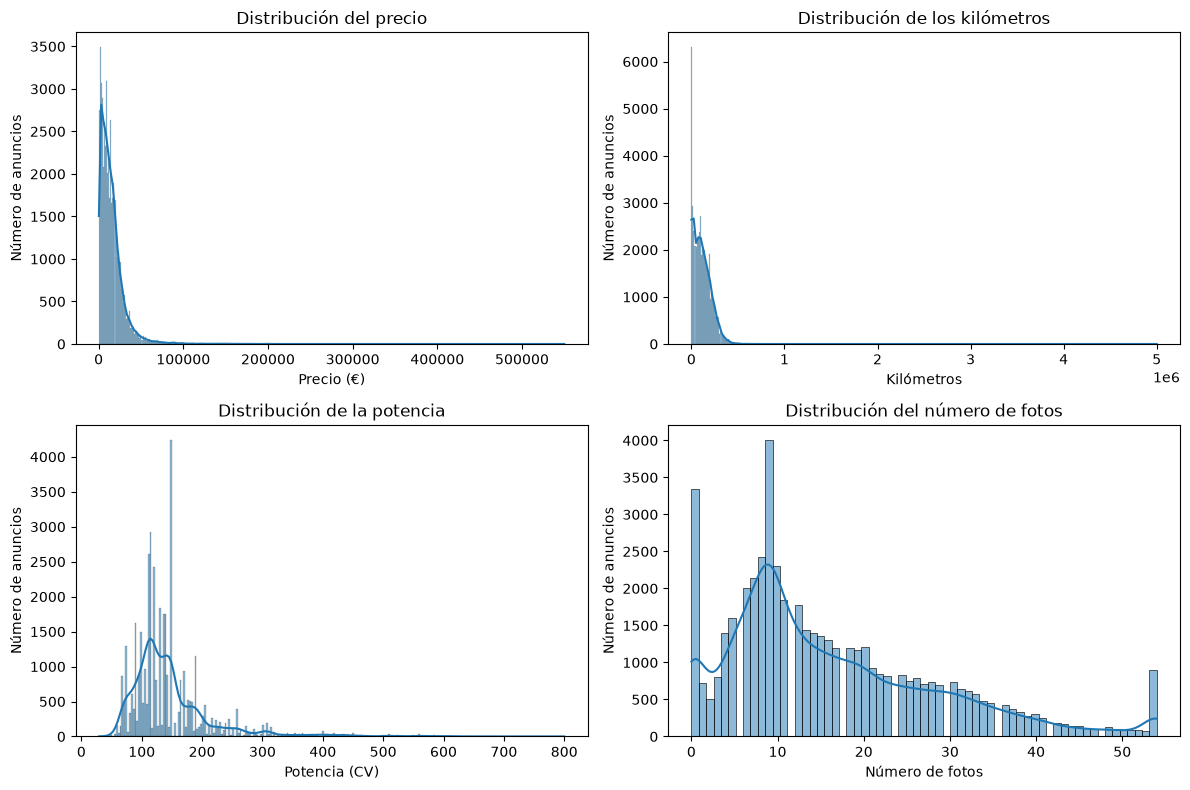

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

columnas = [
    ('price', 'Distribución del precio', 'Precio (€)', axes[0, 0]),
    ('kms', 'Distribución de los kilómetros', 'Kilómetros', axes[0, 1]),
    ('power', 'Distribución de la potencia', 'Potencia (CV)', axes[1, 0]),
    ('photos', 'Distribución del número de fotos', 'Número de fotos', axes[1, 1]),
]

for col, titulo, eje, ax in columnas:
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel(eje)
    ax.set_ylabel('Número de anuncios')

plt.tight_layout()
plt.savefig('../outputs/figures/01_distribucion_variables_numericas.png', bbox_inches='tight')
plt.show()

### Observación: distribuciones

- price: asimetría cerca de 6,6. La mediana es 11.750 € y la media 15.166 €. El máximo llega a 549.900 €. Unos pocos coches muy caros alargan la cola.
- kms: asimetría cerca de 8,3, la más alta. Hay anuncios con 0 km y el máximo es 5.000.000 km, que no es un kilometraje creíble. La mediana cae en 99.999 km, aunque solo 19 anuncios tienen exactamente ese kilometraje.
- power: asimetría cerca de 2,7. Va de 29 a 800 CV, y el gráfico solo incluye los anuncios con potencia. El 17 % de vacíos se decide más adelante.
- photos: asimetría cerca de 1, la más suave. Va de 0 a 54 fotos, y el percentil 99 también es 54. Parece un tope del portal.

Los precios extremos y los kilómetros de relleno se miran en el siguiente bloque. Aquí no quitamos ninguna fila.

### Diagrama de caja

El histograma enseña la forma. El diagrama de caja enseña la mediana, la caja (del percentil 25 al 75) y los puntos que caen fuera de los bigotes. Los bigotes llegan hasta 1,5 veces el rango intercuartílico. Es una regla para señalar la cola, no una prueba de que el dato esté mal. Usamos la misma rejilla de 2 por 2.

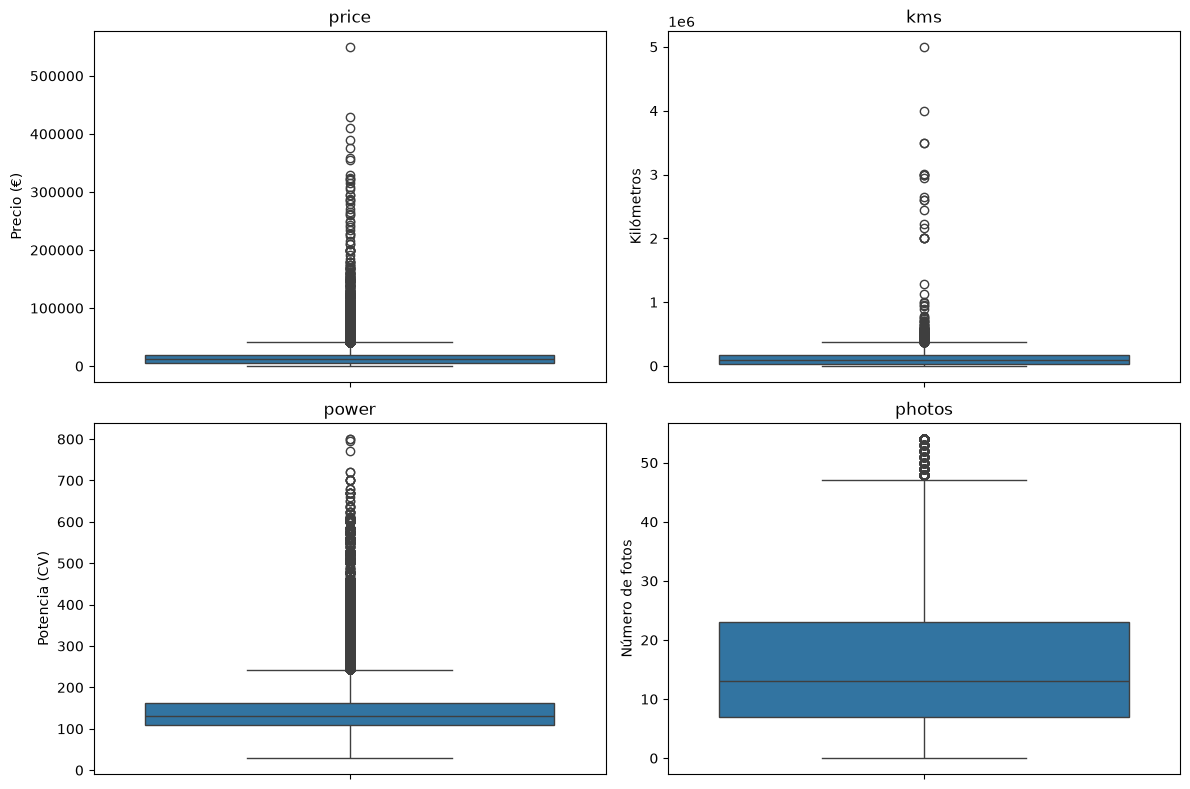

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

columnas = [
    ('price', 'Precio (€)', axes[0, 0]),
    ('kms', 'Kilómetros', axes[0, 1]),
    ('power', 'Potencia (CV)', axes[1, 0]),
    ('photos', 'Número de fotos', axes[1, 1]),
]

for col, eje, ax in columnas:
    sns.boxplot(y=df[col].dropna(), ax=ax)
    ax.set_title(col)
    ax.set_ylabel(eje)

plt.tight_layout()
plt.savefig('../outputs/figures/02_boxplot_variables_numericas.png', bbox_inches='tight')
plt.show()

### Observación: diagramas de caja

- price: el bigote superior acaba hacia 41.250 € y hay unos 2.205 anuncios por encima. Muchos son coches caros de verdad. El punto que se separa es el máximo, 549.900 €.
- kms: el bigote acaba hacia 380.000 km y hay 479 anuncios por encima. 21 llegan al millón de km o más, y uno tiene 5.000.000. El diagrama no marca ni los 0 km ni los 99.999: 99.999 es la mediana, así que cae en el centro de la caja. Esos se juzgan aparte.
- power: el bigote acaba hacia 244 CV y hay unos 3.275 anuncios por encima, hasta 800 CV. Buena parte son coches potentes, no errores.
- photos: el bigote acaba hacia 47 y el máximo es 54. Esos puntos son el tope del portal.

No borramos nada en este cuaderno. El recorte de los casos aislados queda decidido en el bloque siguiente, para el preprocesado.

### Recorte para el preprocesado

Contamos cuántos anuncios quedan por encima de los cortes que estamos valorando, y cuántos tienen exactamente 99.999 km.

In [12]:
print('Vehículos eliminados con precio mayor de 100000 €:', (df['price'] > 100000).sum())
print('Vehículos eliminados con precio menor de 1000 €:', (df['price'] < 1000).sum())
print('Vehículos eliminados con más de 1000000 km:', (df['kms'] > 1000000).sum())
print('Vehículos eliminados con potencia mayor de 700 CV:', (df['power'] > 700).sum())
print('Vehículos con más de 47 fotos (no se eliminan):', (df['photos'] > 47).sum())
print('Vehículos con exactamente 99999 km (no se eliminan):', (df['kms'] == 99999).sum())
eliminados = (df['price'] > 100000) | (df['price'] < 1000) | (df['kms'] > 1000000) | (df['power'] > 700)
print('Total de vehículos eliminados:', eliminados.sum())

Vehículos eliminados con precio mayor de 100000 €: 195
Vehículos eliminados con precio menor de 1000 €: 1012
Vehículos eliminados con más de 1000000 km: 21
Vehículos eliminados con potencia mayor de 700 CV: 6
Vehículos con más de 47 fotos (no se eliminan): 1469
Vehículos con exactamente 99999 km (no se eliminan): 19
Total de vehículos eliminados: 1227


### Decisión: cortes

El orden del recuento es: precio por encima de 100.000 €, kilómetros por encima de 1.000.000, potencia por encima de 700 CV, fotos por encima de 47 y kilómetros exactamente iguales a 99.999.
También voy a eliminar los vehículos de menos de 1.000€ por una decisión de negocio, para una compraventa es mejor no comprar vehículos tan baratos, ya que probablemente sean demasiado antiguos o en mal estado.

Estos cortes no corrigen un error. Un precio alto, muchos kilómetros o mucha potencia pueden ser reales. Los apartamos para que unos pocos coches no dominen el modelo. Eso define a qué coches se aplicará el modelo, así que se hace en el preprocesado, no en la limpieza.

- Precio por encima de 100.000 €: 195 anuncios.
- Precio por debajo de 1.000 €: 1012 anuncios
- Kilómetros por encima de 1.000.000: 21 anuncios.
- Potencia por encima de 700 CV: 6 anuncios. Quien no trae potencia no entra en este corte.
- Juntos, sin contar dos veces el mismo anuncio: 1227 filas (el 2,45 %).

Las fotos se quedan. Por encima del bigote hay 1.469 anuncios y el máximo es 54, el tope del portal. No son casos aislados.

99.999 km exactos: 19 anuncios. La mediana del dataset cae en ese número, pero no hay una masa de anuncios así. Puede ser un relleno y no podemos reconstruir el kilometraje. Se anota como limitación y no se hace nada más.

### Comprobación: ¿tienen gemelos los coches sin potencia?

A 8.528 anuncios les falta la potencia. Antes de decidir cómo rellenarla, medimos si se puede copiar de **coches iguales** que sí la tienen:

1. Primero, coches con la misma marca, modelo y versión (la versión suele fijar el motor).
2. Si no hay, coches con la misma marca y modelo (menos preciso, porque un modelo puede tener varios motores).

Aquí **solo medimos**. El relleno, si se hace, se aplicará en 02_limpieza. El df original no se modifica: trabajamos con copias.

Separamos los anuncios sin potencia y con potencia.

In [ ]:
sin_power = df[df['power'].isnull()].copy()
con_power = df[df['power'].notnull()].copy()
print('Sin potencia:', len(sin_power))
print('Con potencia:', len(con_power))

Sin potencia: 8528
Con potencia: 41472


Creamos una clave de texto con marca, modelo y versión, y otra solo con marca y modelo, para poder comparar.

In [14]:
sin_power['clave_mmv'] = sin_power['make'] + ' | ' + sin_power['model'] + ' | ' + sin_power['version']
con_power['clave_mmv'] = con_power['make'] + ' | ' + con_power['model'] + ' | ' + con_power['version']
sin_power['clave_mm'] = sin_power['make'] + ' | ' + sin_power['model']
con_power['clave_mm'] = con_power['make'] + ' | ' + con_power['model']

Contamos cuántos coches sin potencia tienen un gemelo exacto (marca + modelo + versión) con potencia.

In [15]:
gemelo_mmv = sin_power['clave_mmv'].isin(con_power['clave_mmv'])
print('Con gemelo marca + modelo + versión:', gemelo_mmv.sum())

Con gemelo marca + modelo + versión: 88


De los que no tienen gemelo exacto, contamos cuántos tienen al menos un coche de la misma marca y modelo con potencia.

In [ ]:
restantes = sin_power[~gemelo_mmv]
gemelo_mm = restantes['clave_mm'].isin(con_power['clave_mm'])
print('Restantes sin gemelo exacto:', len(restantes))
print('De ellos, con gemelo marca + modelo:', gemelo_mm.sum())
print('Sin ningún gemelo:', len(restantes) - gemelo_mm.sum())

Restantes sin gemelo exacto: 8440
De ellos, con gemelo marca + modelo: 8332
Sin ningún gemelo: 108


Miramos algunos ejemplos de versión de los coches sin potencia, para entender por qué no encuentran gemelo exacto.

In [17]:
sin_power['version'].value_counts().head(10)

version
BMW              399
VOLKSWAGEN       392
RENAULT          279
MERCEDES-BENZ    266
AUDI             264
PEUGEOT          258
FORD             249
SEAT             248
OPEL             243
CITROEN          191
Name: count, dtype: int64

Por último, contamos cuántos nulos de potencia quedarían si aplicamos los cortes decididos (precio entre 1.000 € y 100.000 €, hasta 1.000.000 km, potencia hasta 700 CV o vacía, y coches de 2006 en adelante). Usamos una copia: df no cambia.

In [18]:
df_cortes = df[(df['price'] >= 1000) & (df['price'] <= 100000) & (df['kms'] <= 1000000) & ((df['power'] <= 700) | (df['power'].isnull())) & (df['year'] >= 2006)]
print('Anuncios tras los cortes:', len(df_cortes))
print('Nulos de potencia tras los cortes:', df_cortes['power'].isnull().sum())

Anuncios tras los cortes: 40801
Nulos de potencia tras los cortes: 3842


### Observaciones (gemelos de los coches sin potencia)

- De los **8.528** anuncios sin potencia, solo **88** (1 %) tienen un gemelo exacto con la misma marca, modelo y versión.
- El motivo se ve en los ejemplos: en muchos de estos anuncios la versión no describe el motor. A menudo es solo la marca ("BMW", "VOLKSWAGEN"...) o marca, modelo y puertas ("RENAULT Laguna 5p."). Por eso casi nunca coinciden con una versión completa.
- De los 8.440 restantes, **8.332** sí tienen coches de la misma marca y modelo con potencia. Solo **108** no tienen ningún gemelo.
- Ojo: un mismo modelo puede llevar motores muy distintos (un Serie 3 puede tener de 116 a más de 400 CV), así que rellenar con la marca y el modelo es una aproximación, no un dato exacto.
- Tras aplicar los cortes decididos (precio de 1.000 € a 100.000 €, hasta 1.000.000 km, potencia hasta 700 CV y coches de 2006 en adelante) quedan **40.801** anuncios y **3.842** siguen sin potencia (el 9,4 %). Los cortes, sobre todo el de antigüedad, eliminan más de la mitad de los nulos, porque se concentraban en coches viejos.
- **Para 02_limpieza:** valorar rellenar la potencia con la mediana de la misma marca y modelo, y decidir qué hacer con los pocos que no tienen gemelo.

## Preguntas e hipótesis

### Hipótesis previas

Estas hipótesis se escribieron **antes de explorar los datos**. Se hace así para no ajustarlas a lo que vemos: si las escribiéramos después, sería muy fácil "acertar" siempre.

- **H1:** los coches de alta gama se deprecian (pierden valor con los años) más rápido.
- **H2:** Volkswagen se deprecia menos que la media.
- **H3:** comparando coches de año similar, los eléctricos son más caros que los diésel, y los diésel más que los gasolina.

En este EDA haremos una **primera validación con gráficos**. En 06_explicabilidad_negocio.ipynb las confirmaremos o refutaremos con SHAP, que muestra cuánto pesa cada variable en el precio que predice el modelo.

### Pregunta 1: ¿Cómo se distribuye el precio y qué valores raros hay?

**Por qué importa para el negocio:** el precio es lo que queremos predecir. Si casi todos los coches están en un rango y unos pocos son muy baratos o muy caros, debemos saberlo. Esos extremos pueden ser errores, chatarra o superdeportivos que la empresa no compraría, y pueden desviar el modelo. Además, conocer el rango habitual nos dice para qué coches será fiable la tasación.

**Lo que ya tenemos más arriba** (no lo repetimos):
- *Resumen de las variables numéricas* (df.describe()): mínimo 300 €, mediana 11.750 €, media 15.166 €, máximo 549.900 €.
- *Distribución de las variables numéricas* (histograma de price): cola larga a la derecha, asimetría ≈ 6,6.
- *Diagrama de caja*: el bigote acaba hacia 41.250 € y hay unos 2.205 anuncios por encima.
- *Recorte para el preprocesado* y *Decisión: cortes*: 7 anuncios por encima de 350.000 €.

Nos falta mirar **el extremo barato**, **los percentiles** y **el precio en escala logarítmica**.

### El precio en escala logarítmica

El precio tiene una cola muy larga a la derecha (asimetría ≈ 6,6): muchos coches baratos y pocos muy caros. El logaritmo "comprime" los valores grandes, de modo que una subida de 5.000 a 10.000 € ocupa lo mismo que de 50.000 a 100.000 €. Así vemos mejor la forma real de la distribución y comprobamos si al modelo le vendría bien predecir el log del precio.

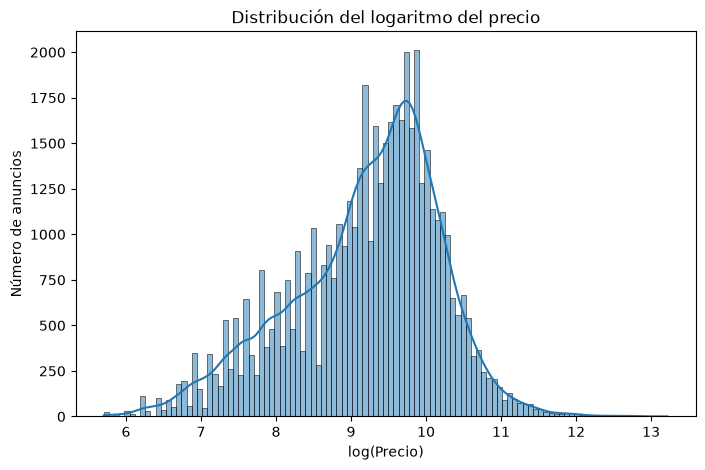

In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(np.log(df['price']), kde=True)
plt.title('Distribución del logaritmo del precio')
plt.xlabel('log(Precio)')
plt.ylabel('Número de anuncios')
plt.savefig('../outputs/figures/03_distribucion_log_precio.png', bbox_inches='tight')
plt.show()

Contamos los coches con precio muy bajo y muy alto, y miramos los percentiles 1 y 99. Arriba solo habíamos mirado el extremo caro.

In [20]:
print('Coches con precio menor de 1.000 €:', (df['price'] < 1000).sum())
print('Coches con precio mayor de 100.000 €:', (df['price'] > 100000).sum())
print('Percentil 1:', df['price'].quantile(0.01))
print('Percentil 99:', df['price'].quantile(0.99))

Coches con precio menor de 1.000 €: 1012
Coches con precio mayor de 100.000 €: 195
Percentil 1: 750.0
Percentil 99: 72900.90000000018


### Observaciones (Pregunta 1)

- Juntando lo de arriba: el precio va de **300 €** a **549.900 €**, con mediana **11.750 €** y media **15.166 €**. La media sube por los coches muy caros.
- **Extremo barato:** hay **1.012** coches por debajo de 1.000 € (el 2 %). No lo habíamos mirado: el diagrama de caja no los marca, porque la cola está a la derecha.
- **Extremo caro:** **195** coches por encima de 100.000 € (el 0,4 %), de los que solo 7 pasan de 350.000 €.
- **Percentiles:** el 1 % es **750 €** y el 99 % es **72.901 €**. El 98 % de los anuncios cae en ese rango.
- **Escala logarítmica:** la asimetría baja de ≈ 6,6 a ≈ **−0,5** y la distribución se parece mucho más a una campana.



### Pregunta 2: ¿Cuánto se deprecia un coche por cada año de antigüedad?

**Por qué importa para el negocio:** la antigüedad es, junto con los kilómetros, lo primero que mira un tasador. Saber cuánto valor pierde de media un coche cada año nos da una regla sencilla para comprobar que el modelo tiene sentido, y es la base para estudiar las hipótesis H1 (alta gama) y H2 (Volkswagen).

Para esta pregunta usamos una copia, df_p2, con los cortes de precio que hemos decidido arriba (entre 1.000 € y 100.000 €). Así los coches de desguace y los superdeportivos no distorsionan la mediana. El df original no se modifica.

In [ ]:
df_p2 = df[(df['price'] >= 1000) & (df['price'] <= 100000)]
df_p2.shape

(48793, 21)

Calculamos la mediana del precio por año de fabricación, desde 2000 hasta 2020. Usamos la mediana y no la media porque el precio tiene cola a la derecha. Dejamos fuera 2021 porque el dataset se capturó el 15-01-2021 y hay muy pocos anuncios de ese año.

In [22]:
df_p2_años = df_p2[(df_p2['year'] >= 2000) & (df_p2['year'] <= 2020)]
mediana_año = df_p2_años.groupby('year')['price'].median()
mediana_año

year
2000.0     2162.5
2001.0     2000.0
2002.0     2300.0
2003.0     2550.0
2004.0     2900.0
2005.0     3490.0
2006.0     3999.0
2007.0     4700.0
2008.0     5900.0
2009.0     6500.0
2010.0     7490.0
2011.0     8900.0
2012.0     9800.0
2013.0    11000.0
2014.0    12300.0
2015.0    14400.0
2016.0    15490.0
2017.0    16900.0
2018.0    16950.0
2019.0    20500.0
2020.0    24990.0
Name: price, dtype: float64

Cuántos anuncios hay en cada año, para saber si cada mediana se apoya en suficientes coches.

In [23]:
df_p2_años['year'].value_counts().sort_index()

year
2000.0     554
2001.0     653
2002.0     888
2003.0    1061
2004.0    1496
2005.0    1791
2006.0    1828
2007.0    2179
2008.0    1841
2009.0    1440
2010.0    1622
2011.0    1531
2012.0    1393
2013.0    1491
2014.0    1979
2015.0    3061
2016.0    5202
2017.0    4447
2018.0    3896
2019.0    4411
2020.0    4167
Name: count, dtype: int64

Gráfico de líneas de la mediana del precio por año.

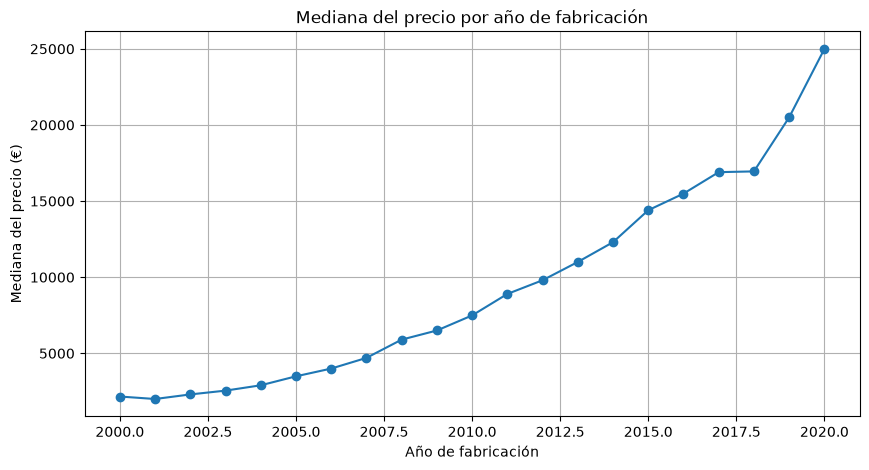

In [24]:
plt.figure(figsize=(10, 5))
plt.plot(mediana_año.index, mediana_año.values, marker='o')
plt.title('Mediana del precio por año de fabricación')
plt.xlabel('Año de fabricación')
plt.ylabel('Mediana del precio (€)')
plt.grid(True)
plt.savefig('../outputs/figures/04_mediana_precio_por_anio.png', bbox_inches='tight')
plt.show()

Calculamos cuánto se pierde al pasar de un año al anterior: si un coche de 2019 vale de mediana 20.500 € y uno de 2018 vale 16.950 €, un año más de antigüedad supone perder un 17 %. Lo hacemos para todos los años y sacamos la media y la mediana de esas pérdidas.

In [25]:
perdida_anual = (1 - mediana_año / mediana_año.shift(-1)) * 100
perdida_anual.round(1)

year
2000.0    -8.1
2001.0    13.0
2002.0     9.8
2003.0    12.1
2004.0    16.9
2005.0    12.7
2006.0    14.9
2007.0    20.3
2008.0     9.2
2009.0    13.2
2010.0    15.8
2011.0     9.2
2012.0    10.9
2013.0    10.6
2014.0    14.6
2015.0     7.0
2016.0     8.3
2017.0     0.3
2018.0    17.3
2019.0    18.0
2020.0     NaN
Name: price, dtype: float64

In [26]:
print('Pérdida media por año de antigüedad (%):', round(perdida_anual.mean(), 1))
print('Pérdida mediana por año de antigüedad (%):', round(perdida_anual.median(), 1))

Pérdida media por año de antigüedad (%): 11.3
Pérdida mediana por año de antigüedad (%): 12.4


### Observaciones (Pregunta 2)

- Para esta pregunta quedan **48.793** anuncios con precio entre 1.000 € y 100.000 €. Todos los años de 2000 a 2020 tienen al menos 554 anuncios, así que cada mediana se apoya en bastantes coches.
- La mediana baja de forma muy regular con la antigüedad: **24.990 €** para un coche de 2020, **14.400 €** para uno de 2015, **7.490 €** para uno de 2010 y **2.162 €** para uno de 2000.
- De media, **cada año de antigüedad resta alrededor de un 11-12 % del precio** (media 11,3 %, mediana 12,4 %). Como es un porcentaje, el coche pierde más euros cuando es nuevo que cuando ya es viejo: la curva es exponencial, no una recta.
- Los primeros años son los que más pesan: de 2020 a 2019 se pierde un 18 % y de 2019 a 2018 un 17,3 %.
- Hay saltos raros: de 2018 a 2017 casi no baja (0,3 %), y de 2001 a 2000 el precio incluso sube (+8,1 %). Pueden deberse a cambios en qué coches se anuncian cada año (más marcas premium o más kilómetros en unos años que en otros). Por eso la cifra es orientativa y la estudiaremos por marca.
- El salto de 2001 a 2000 se explica probablemente por **sesgo de supervivencia**: con más de 20 años solo siguen a la venta los coches bien conservados o apreciados (los demás ya se han desguazado), y además hay menos anuncios. Por eso, a partir de unos 15-20 años de antigüedad la depreciación deja de ser fiable.
- **Relación con las hipótesis:** esta cifra del 11-12 % anual es la referencia de "la media". Para **H1** compararemos la depreciación de las marcas de alta gama con este valor; para **H2**, la de Volkswagen. Todavía no concluimos nada: lo veremos por marca y lo confirmaremos con SHAP en 06_explicabilidad_negocio.
- **Idea para el modelado:** como la caída es exponencial, el logaritmo del precio baja casi en línea recta con el año. Es otro motivo para probar a predecir log(price), como se propuso en la Pregunta 1.
- **Propuesta para 03_preprocesado:** cortar por antigüedad y quedarnos con coches de **hasta 15 años** (fabricados en 2006 o después, ya que los datos se capturaron en 2021). Es una decisión de negocio: la empresa se centra en coches de 0 a 15 años, donde la caída del precio es clara y predecible. Dentro del rango de 1.000 € a 100.000 €, se perderían **7.979 anuncios** de 2005 o antes, el **16,4 %** de los 48.793.

## Conclusiones del EDA y próximos pasos

**Lo que hemos aprendido hasta ahora:**
- El dataset tiene 50.000 anuncios y 21 columnas, y la variable objetivo es price.
- price_financed está vacía en más de la mitad de las filas y va casi a la par que price.
- power tiene un 17 % de nulos, concentrados en coches viejos y baratos, pero es una variable clave.
- Faltan pocos datos en el resto: make (2), model (5), year (2), fuel (46), shift (111), color (594) y province (6).
- price, kms y power tienen cola a la derecha. En kilómetros el máximo es 5.000.000. La mediana es 99.999, pero solo 19 anuncios tienen exactamente ese valor. photos llega a 54, que parece un tope.
- url y company no describen el coche.

**Decisiones para 02_limpieza.ipynb:**
1. Eliminar price_financed.
2. Rellenar la marca de los D2S con INVICTA ELECTRIC.
3. Quitar url y company (y valorar country y dealer).
4. Mantener power y elegir más adelante cómo rellenarla.
5. Revisar uno a uno el resto de nulos (incluidos los 5 de model).
6. Convertir year a entero (int16) tras tratar sus 2 nulos. El año no tiene decimales; int16 basta y reduce memoria (int64 ocupa lo mismo que float64).

**Decisiones para el preprocesado:**
1. Quitar los anuncios con precio por encima de 350.000 €, kilómetros por encima de 1.000.000 o potencia por encima de 700 CV. Son 32 anuncios (el 0,06 %). Pueden ser reales, pero son casos aislados y moverían el modelo.
2. Dejar el número de fotos como está. Por encima del bigote hay 1.469 anuncios y el máximo es 54, el tope del portal.
3. Anotar como limitación los 19 anuncios con 99.999 km. No se imputan ni se borran solo por eso.

**Pendiente en este EDA:**
- Responder a las preguntas 1 a 7 del README.
- Explorar las hipótesis H1, H2 y H3.